In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
dataset=pd.read_excel(r"C:\Users\dell\Downloads\1775106859-Financial_Sample.xlsx")
dataset.head(4)

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year
0,Government,Canada,Carretera,NaN,1618.5,3,20.0,32370.0,0.0,32370.0,16185.0,16185.0,2014-01-01,1,January,2014
1,Government,Germany,Carretera,NaN,1321.0,3,20.0,26420.0,0.0,26420.0,13210.0,13210.0,2014-01-01,1,January,2014
2,Midmarket,France,Carretera,NaN,2178.0,3,15.0,32670.0,0.0,32670.0,21780.0,10890.0,2014-06-01,6,June,2014
3,Midmarket,Germany,Carretera,NaN,888.0,3,15.0,13320.0,0.0,13320.0,8880.0,4440.0,2014-06-01,6,June,2014


sns.boxplot(x=dataset["Gross Sales"], data=dataset)

Ye Gross Sales column ka box plot banata hai, jisse hum data ki distribution aur outliers easily identify kar sakte hain.

🔍 Code ko break karke samjho

sns.boxplot()
→ Seaborn ka function hai jo box plot banata hai.

x=dataset["Gross Sales"]
→ Gross Sales column ko X-axis par plot karo.

data=dataset
→ Data source dataset DataFrame hai.

📦 Box plot kya dikhata hai?

Box plot roughly aisa dikhta hai:

        |----------- Whisker -----------|
                    ┌───────────┐
───────────────|────│   BOX     │────|────────────
                    └───────────┘

Isme mainly:

Box → middle 50% data (Q1 to Q3)
Middle line → Median
Whiskers → normal range
Dots → possible outliers
🚨 Example

Agar Gross Sales mein:

1000
1200
1100
1300
1250
50000

To 50000 baaki values se bahut different hai, so boxplot usko outlier ke roop mein show kar sakta hai.

⭐ Important

Aapke code mein data=dataset technically zaroori nahi hai, kyunki aap already Series pass kar rahe ho.

Ye bhi kaam karega:

sns.boxplot(x=dataset["Gross Sales"])

Aur agar DataFrame syntax use karna ho:

sns.boxplot(x="Gross Sales", data=dataset)

Ye wala syntax zyada clean/recommended hai: ✅

sns.boxplot(x="Gross Sales", data=dataset)

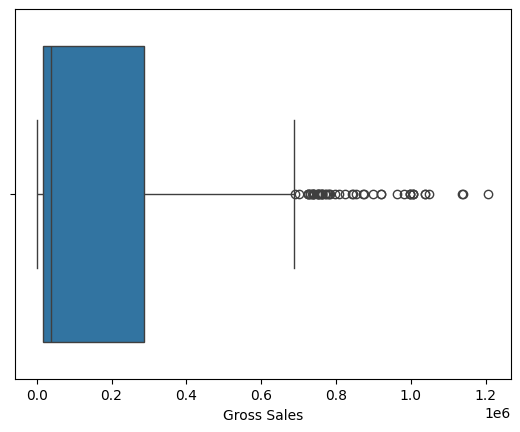

In [9]:
sns.boxplot(x=dataset["Gross Sales"],data=dataset)
plt.show()

In [10]:
dataset.shape

(700, 16)

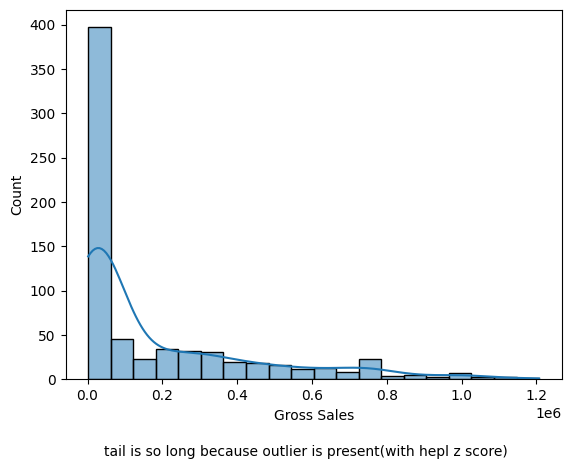

In [13]:
sns.histplot(dataset['Gross Sales'],kde=True)
plt.figtext(0.5, -0.05, "tail is so long because outlier is present(with hepl z score)",
            ha="center")
plt.show()

plt.figtext(0.5, -0.10, "Note: Outliers are represented by individual points.",
            ha="center")
🔹 plt.figtext()

figtext() ka use poore figure ke andar/around text add karne ke liye hota hai.

Yahan hum graph ke bottom mein note add kar rahe hain.

🔹 0.5
plt.figtext(0.5, ...)

Ye X-position hai.

Matplotlib mein generally:

0 -------- 0.5 -------- 1
Left       Center       Right

So 0.5 = center.

🔹 -0.10
plt.figtext(0.5, -0.10, ...)

Ye Y-position hai.

  1   ↑ Top
      |
  0   → Figure
      |
-0.10 ↓ Bottom

-0.10 ka matlab hai text ko figure ke bottom ke thoda neeche place karo.

🔹 "Note: ..."
"Note: Outliers are represented by individual points."

Ye simply aapka comment/note hai jo graph ke neeche display hoga.

Aap kuch bhi likh sakte ho:

plt.figtext(0.5, -0.10, "This graph shows Gross Sales distribution.",
            ha="center")
🔹 ha="center"

ha = horizontal alignment

ha="center"

Matlab text ko center align karo.

Agar:

ha="left"

→ left aligned

ha="right"

→ right aligned

⭐ Complete meaning
plt.figtext(0.5, -0.10, "Note: Outliers are represented by individual points.",
            ha="center")

Simple Hinglish:

"Figure ke horizontal center (0.5) par, figure ke bottom se thoda neeche (-0.10), ye note likho aur usko center-align (ha="center") karo."

📌 Easy formula yaad rakho:
plt.figtext(X, Y, "TEXT", ha="alignment")

X → left/right
Y → up/down
TEXT → kya likhna hai
ha → text alignment

In [ ]:
min_range = dataset['Gross Sales'].mean() - (3 * dataset['Gross Sales'].std())
                                                                                            #there is no need to find min max range
max_range = dataset['Gross Sales'].mean() + (3 * dataset['Gross Sales'].std())

In [17]:
min_range,max_range

(np.float64(-580357.6110666066), np.float64(948291.6959586928))

In [18]:
n_dataset=dataset[dataset["Gross Sales"]<max_range]

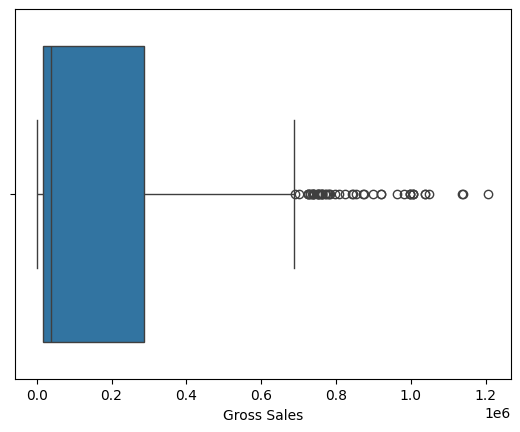

In [19]:
sns.boxplot(x=dataset["Gross Sales"],data=n_dataset)
plt.show()

Z-score = (Value − Mean) / Standard Deviation

True ka matlab → value mean se 3 standard deviations se zyada above hai → potential outlier.

🔥 Dono side ke outliers find karne hain

Sirf:

z_score > 3

se upper outliers milenge.

Lower + upper dono ke liye:

z_score.abs() > 3

Example:  

outliers = dataset[z_score.abs() > 3]  
⭐ Yaad rakho  
Z-score > +3  → Upper outlier  
Z-score < -3  → Lower outlier  
|Z-score| > 3  → Both outliers  

So aapke case mein correct approach:  

z_score = (dataset['Gross Sales'] - dataset['Gross Sales'].mean()) / dataset['Gross Sales'].std()

outliers = dataset[z_score.abs() > 3]

In [21]:
#find z_score
z_score=(dataset['Gross Sales']-dataset["Gross Sales"].mean())/(dataset["Gross Sales"].std())
z_score>3

0      False
1      False
2      False
3      False
4      False
       ...  
695    False
696    False
697    False
698    False
699    False
Name: Gross Sales, Length: 700, dtype: bool

In [22]:
dataset.shape

(700, 16)

In [ ]:
dataset["z_score"]=z_score # Z-score ko new column mein save karo

z_score         # Z-score values dekho


0     -0.595023
1     -0.618377
2     -0.593846
3     -0.669795
4     -0.576654
         ...   
695    2.192261
696   -0.079156
697   -0.684491
698   -0.702212
699   -0.637014
Name: Gross Sales, Length: 700, dtype: float64

In [25]:
#z_score outlier remove consider down 3rd
dataset[dataset["z_score"]<3]               # Z-score outlier remove: 3 se neeche values rakho
                                            # Sirf Z-score < 3 wali rows rakho

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year,z_score
0,Government,Canada,Carretera,NaN,1618.5,3,20.0,32370.0,0.00,32370.00,16185.0,16185.00,2014-01-01,1,January,2014,-0.595023
1,Government,Germany,Carretera,NaN,1321.0,3,20.0,26420.0,0.00,26420.00,13210.0,13210.00,2014-01-01,1,January,2014,-0.618377
2,Midmarket,France,Carretera,NaN,2178.0,3,15.0,32670.0,0.00,32670.00,21780.0,10890.00,2014-06-01,6,June,2014,-0.593846
3,Midmarket,Germany,Carretera,NaN,888.0,3,15.0,13320.0,0.00,13320.00,8880.0,4440.00,2014-06-01,6,June,2014,-0.669795
4,Midmarket,Mexico,Carretera,NaN,2470.0,3,15.0,37050.0,0.00,37050.00,24700.0,12350.00,2014-06-01,6,June,2014,-0.576654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
695,Small Business,France,Amarilla,High,2475.0,260,300.0,742500.0,111375.00,631125.00,618750.0,12375.00,2014-03-01,3,March,2014,2.192261
696,Small Business,Mexico,Amarilla,High,546.0,260,300.0,163800.0,24570.00,139230.00,136500.0,2730.00,2014-10-01,10,October,2014,-0.079156
697,Government,Mexico,Montana,High,1368.0,5,7.0,9576.0,1436.40,8139.60,6840.0,1299.60,2014-02-01,2,February,2014,-0.684491
698,Government,Canada,Paseo,High,723.0,10,7.0,5061.0,759.15,4301.85,3615.0,686.85,2014-04-01,4,April,2014,-0.702212


In [26]:
#Note: Agar aapko lower aur upper dono outliers remove karne hain, to better:

dataset[dataset["z_score"].abs() < 3]
# -3 se +3 ke beech wali rows rakho

# Student shortcut:
# < 3 → upper outliers remove
# abs() < 3 → both-side outliers remove ✅

,Segment,Country,Product,Discount Band,Units Sold,Manufacturing Price,Sale Price,Gross Sales,Discounts,Sales,COGS,Profit,Date,Month Number,Month Name,Year,z_score
0,Government,Canada,Carretera,NaN,1618.5,3,20.0,32370.0,0.00,32370.00,16185.0,16185.00,2014-01-01,1,January,2014,-0.595023
1,Government,Germany,Carretera,NaN,1321.0,3,20.0,26420.0,0.00,26420.00,13210.0,13210.00,2014-01-01,1,January,2014,-0.618377
2,Midmarket,France,Carretera,NaN,2178.0,3,15.0,32670.0,0.00,32670.00,21780.0,10890.00,2014-06-01,6,June,2014,-0.593846
3,Midmarket,Germany,Carretera,NaN,888.0,3,15.0,13320.0,0.00,13320.00,8880.0,4440.00,2014-06-01,6,June,2014,-0.669795
4,Midmarket,Mexico,Carretera,NaN,2470.0,3,15.0,37050.0,0.00,37050.00,24700.0,12350.00,2014-06-01,6,June,2014,-0.576654
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
695,Small Business,France,Amarilla,High,2475.0,260,300.0,742500.0,111375.00,631125.00,618750.0,12375.00,2014-03-01,3,March,2014,2.192261
696,Small Business,Mexico,Amarilla,High,546.0,260,300.0,163800.0,24570.00,139230.00,136500.0,2730.00,2014-10-01,10,October,2014,-0.079156
697,Government,Mexico,Montana,High,1368.0,5,7.0,9576.0,1436.40,8139.60,6840.0,1299.60,2014-02-01,2,February,2014,-0.684491
698,Government,Canada,Paseo,High,723.0,10,7.0,5061.0,759.15,4301.85,3615.0,686.85,2014-04-01,4,April,2014,-0.702212


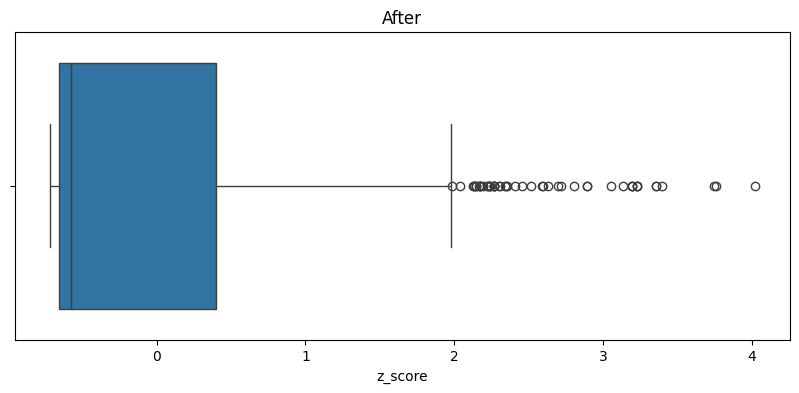

In [31]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=dataset["z_score"])
# Z-score ka boxplot banao

plt.title("After")
# Graph ka title set karo

plt.show()
# Graph display karo

In [32]:
(dataset["z_score"].abs() >= 3).sum()

np.int64(14)